# 04 — Machine Learning Experiments
**Research question:** Can handcrafted acoustic features recognize unseen-speaker emotion, and can reduced model complexity improve generalization?

Train actors 01–12 are used for speaker-grouped CV; fixed validation actors 13–18 support model choice. Test actors 19–24 are reserved for descriptive evaluation in 05. This notebook compares six original model families, studies the acoustic feature space and ablation, then performs a bounded regularization study. The test set is **not** used to tune these experiments.

## 1. Environment and plotting style

In [ ]:
from pathlib import Path
import hashlib, json, platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score, f1_score,
                             accuracy_score, balanced_accuracy_score)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
SEED = 42
PROJECT_DIR = Path('/content/drive/MyDrive/speech-emotion-recognition-project-d')
FEATURES_PATH = PROJECT_DIR / 'data/processed/ravdess_features.csv'
OUTPUT_DIR = PROJECT_DIR / 'results/04_ml'
METRICS_DIR, FIGURES_DIR = OUTPUT_DIR / 'metrics', OUTPUT_DIR / 'figures'
for folder in (METRICS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)
if not FEATURES_PATH.is_file():
    raise FileNotFoundError(FEATURES_PATH)

Mounted at /content/drive


In [ ]:
PURPLE, BLUE, DARK_PURPLE = '#B57EDC', '#2A52BE', '#9461B5'
PALE = '#FAF9FC'
DIVERGING = LinearSegmentedColormap.from_list('blue_lavender', [BLUE, PALE, PURPLE])
SEQUENTIAL = LinearSegmentedColormap.from_list('lavender', ['#FFFFFF', '#E4CBF2', PURPLE, DARK_PURPLE])
MODEL_COLORS = [BLUE, PURPLE, '#9461B5', '#6A8AC8', '#B8A0CB', '#64748B']
sns.set_theme(style='white', font_scale=.94)

def style_ax(ax, title, grid='y'):
    ax.set_title(title, loc='left', fontweight='bold', pad=13)
    ax.grid(axis=grid, ls='--', alpha=.18)
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=0, labelrotation=0)
    sns.despine(ax=ax)

def save_plot(fig, name):
    fig.savefig(FIGURES_DIR / name, dpi=170, bbox_inches='tight')
    plt.show()

def pretty(name):
    return {'dummy_most_frequent':'Dummy', 'logistic_regression':'Logistic Regression',
            'svm_linear':'Linear SVM', 'svm_rbf':'RBF SVM',
            'random_forest':'Random Forest', 'extra_trees':'Extra Trees'}.get(name, name)

## 2. Data and speaker-independent protocol

In [ ]:
df = pd.read_csv(FEATURES_PATH).sort_values('relative_path').reset_index(drop=True)
EMOTIONS = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
MFCC = [f'mfcc_{i:02d}_{s}' for i in range(1,14) for s in ('mean','std')]
PROSODIC = [f'{name}_{s}' for name in ('rms','zcr') for s in ('mean','std')] + ['f0_hz_mean','f0_hz_std','voiced_ratio']
SPECTRAL = [f'{name}_{s}' for name in ('spectral_centroid','spectral_bandwidth','spectral_rolloff') for s in ('mean','std')]
FEATURE_COLS = MFCC + [f'{name}_{s}' for name in ('rms','zcr','spectral_centroid','spectral_bandwidth','spectral_rolloff') for s in ('mean','std')] + ['f0_hz_mean','f0_hz_std','voiced_ratio']
FEATURE_SETS = {'MFCC (26)':MFCC, 'Prosodic (7)':PROSODIC, 'Spectral (6)':SPECTRAL, 'Combined (39)':FEATURE_COLS}
assert len(FEATURE_COLS)==39 and len(set(FEATURE_COLS))==39
assert set(MFCC+PROSODIC+SPECTRAL)==set(FEATURE_COLS)
assert len(df)==1440 and df.relative_path.is_unique
assert {'relative_path','emotion','actor_id',*FEATURE_COLS}.issubset(df.columns)
assert np.isfinite(df[FEATURE_COLS].to_numpy(dtype=float)).all()
X, y, actors = df[FEATURE_COLS], df.emotion, df.actor_id.astype(int)
assert set(y)==set(EMOTIONS) and set(actors)==set(range(1,25))
train_mask, val_mask, test_mask = actors.between(1,12), actors.between(13,18), actors.between(19,24)
X_train, X_val = X.loc[train_mask].reset_index(drop=True), X.loc[val_mask].reset_index(drop=True)
y_train, y_val = y.loc[train_mask].reset_index(drop=True), y.loc[val_mask].reset_index(drop=True)
g_train, g_val = actors.loc[train_mask].reset_index(drop=True), actors.loc[val_mask].reset_index(drop=True)
assert (len(X_train),len(X_val),int(test_mask.sum()))==(720,360,360)
assert set(g_train).isdisjoint(g_val)
cv = GroupKFold(n_splits=3)
cv_splits = list(cv.split(X_train, y_train, groups=g_train))
assert all(set(g_train.iloc[a]).isdisjoint(g_train.iloc[b]) for a,b in cv_splits)
DATA_SHA256 = hashlib.sha256(FEATURES_PATH.read_bytes()).hexdigest()
display(pd.DataFrame({'Split':['Train','Validation','Reserved test'], 'Actors':['01–12','13–18','19–24'], 'Recordings':[720,360,360]}))
print(f'39 acoustic features; data SHA256: {DATA_SHA256[:16]}…')

,Split,Actors,Recordings
0,Train,01–12,720
1,Validation,13–18,360
2,Reserved test,19–24,360


39 acoustic features; data SHA256: 4c40d711fff32289…


## 3. PCA: acoustic feature space
PCA is fitted only on standardized training-speaker features. Each small panel highlights one emotion in the **same PC1–PC2 coordinate system**; gray points show all remaining emotions. The separate explained-variance plot indicates how much information the 2D projection omits. PCA is unsupervised and its components are not classification boundaries.

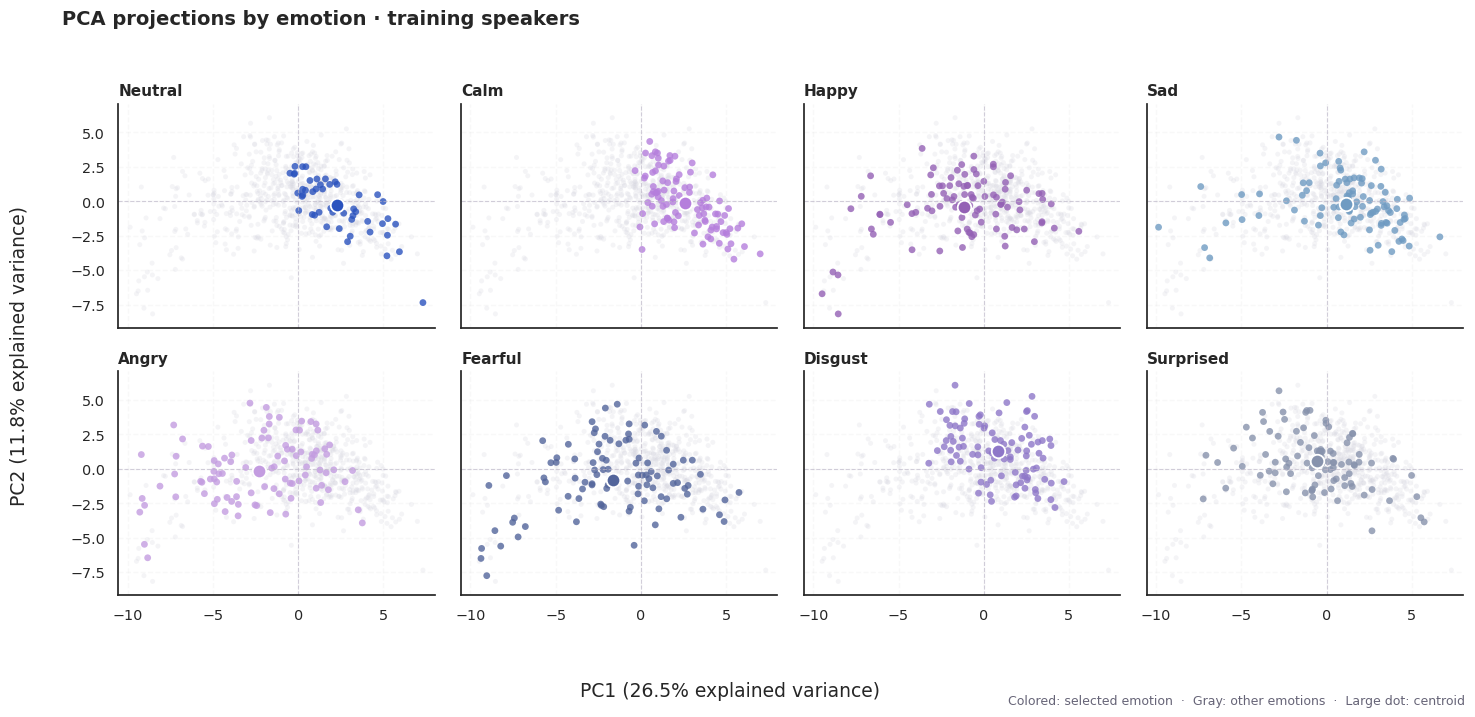

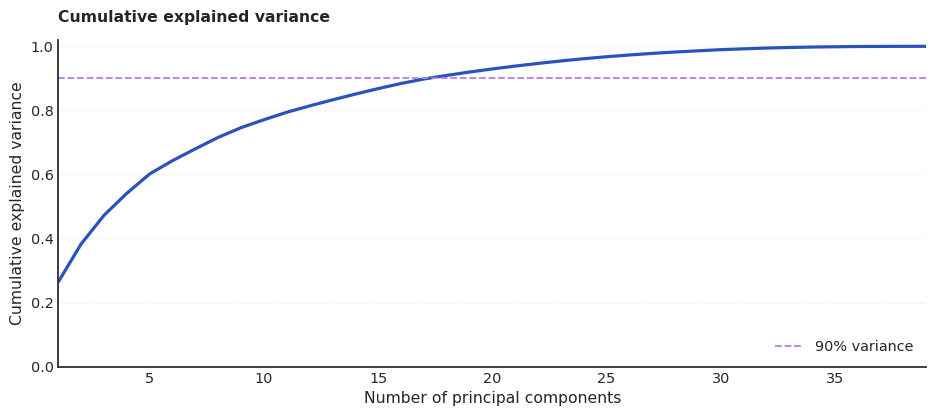

First two PCs explain 38.3% of total variance.
18 components are needed to retain at least 90% (90.9%).


In [ ]:
# Exploratory PCA uses TRAIN actors only (no validation/test leakage).
scaled = StandardScaler().fit_transform(X_train)
pca = PCA(random_state=SEED).fit(scaled)
points = pca.transform(scaled)
labels = y_train.to_numpy()
colors = ['#2A52BE', '#B57EDC', '#9461B5', '#6F9BC2',
          '#C39CE0', '#53659B', '#8E77C8', '#8792AC']

# Faceted view: one highlighted emotion per panel, with comparable axes.
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharex=True, sharey=True)
x_pad, y_pad = np.ptp(points[:, 0]) * .04, np.ptp(points[:, 1]) * .07
for ax, emotion, color in zip(axes.flat, EMOTIONS, colors):
    selected = (labels == emotion)
    ax.scatter(points[~selected, 0], points[~selected, 1],
               s=13, c='#D6D6E0', alpha=.26, edgecolors='none', rasterized=True)
    ax.scatter(points[selected, 0], points[selected, 1],
               s=24, c=color, alpha=.80, edgecolors='none', rasterized=True)
    ax.scatter(points[selected, 0].mean(), points[selected, 1].mean(),
               s=95, c=color, edgecolors='white', linewidths=1.3, zorder=5)
    ax.axhline(0, color='#BBB5C7', lw=.8, ls='--', alpha=.65)
    ax.axvline(0, color='#BBB5C7', lw=.8, ls='--', alpha=.65)
    ax.set_title(emotion.capitalize(), loc='left', fontweight='bold', fontsize=11)
    ax.set_xlim(points[:, 0].min()-x_pad, points[:, 0].max()+x_pad)
    ax.set_ylim(points[:, 1].min()-y_pad, points[:, 1].max()+y_pad)
    ax.grid(alpha=.12, ls='--')
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

fig.supxlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} explained variance)', y=.02)
fig.supylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} explained variance)', x=.02)
fig.suptitle('PCA projections by emotion · training speakers',
             x=.055, ha='left', fontweight='bold', fontsize=14)
fig.text(.99, .015, 'Colored: selected emotion  ·  Gray: other emotions  ·  Large dot: centroid',
         ha='right', fontsize=9, color='#666477')
plt.tight_layout(rect=(.025, .055, 1, .95), w_pad=1.2, h_pad=1.5)
save_plot(fig, 'pca_train.png')

# A separate cumulative variance curve (no clutter at the threshold).
cumulative = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(cumulative, .90) + 1)
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.plot(np.arange(1, len(cumulative)+1), cumulative,
        color=BLUE, lw=2.3)
ax.axhline(.90, color=PURPLE, lw=1.3, ls='--', label='90% variance')
ax.set(xlabel='Number of principal components',
       ylabel='Cumulative explained variance',
       ylim=(0, 1.02), xlim=(1, len(cumulative)))
style_ax(ax, 'Cumulative explained variance', grid='y')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
save_plot(fig, 'pca_explained_variance.png')
print(f'First two PCs explain {cumulative[1]:.1%} of total variance.')
print(f'{n90} components are needed to retain at least 90% ({cumulative[n90-1]:.1%}).')

## 4. Unsupervised clustering
Silhouette measures geometric cohesion; ARI compares cluster IDs with emotion labels. Neither assumes that emotional categories must form spherical clusters.

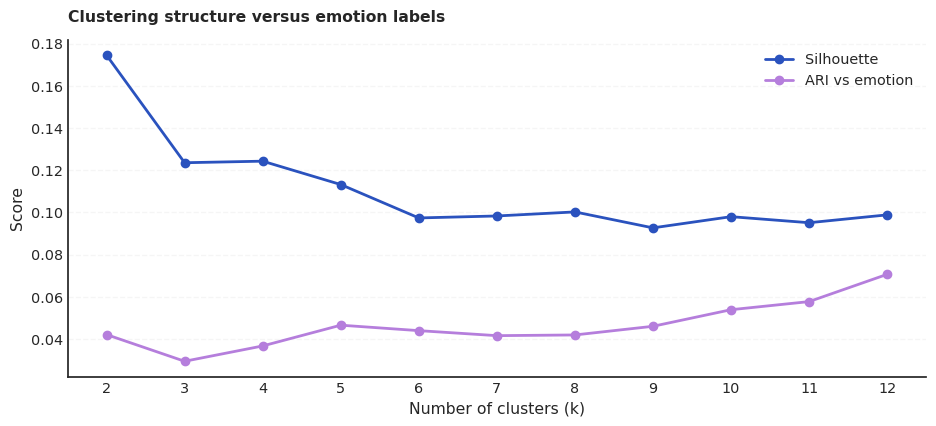

,k,silhouette,ARI_vs_emotion
0,2,0.175,0.042
1,3,0.124,0.029
2,4,0.124,0.037
3,5,0.113,0.047
4,6,0.097,0.044
5,7,0.098,0.042
6,8,0.100,0.042
7,9,0.093,0.046
8,10,0.098,0.054
9,11,0.095,0.058


At k=8: silhouette = 0.100; ARI = 0.042.


In [ ]:
# K-Means explores natural structure; k=8 is the prespecified number of emotion labels.
# The silhouette profile over several k values is descriptive, not used to tune the supervised model.
rows = []
for k in range(2, 13):
    cluster_id = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(scaled)
    rows.append({'k':k, 'silhouette':silhouette_score(scaled, cluster_id),
                 'ARI_vs_emotion':adjusted_rand_score(y_train, cluster_id)})
cluster_df = pd.DataFrame(rows)
cluster_df.to_csv(METRICS_DIR/'train_clustering.csv',index=False)
fig, ax = plt.subplots(figsize=(9.5,4.4))
ax.plot(cluster_df.k,cluster_df.silhouette,marker='o',color=BLUE,lw=2,label='Silhouette')
ax.plot(cluster_df.k,cluster_df.ARI_vs_emotion,marker='o',color=PURPLE,lw=2,label='ARI vs emotion')
ax.set(xlabel='Number of clusters (k)', ylabel='Score',xticks=list(range(2,13)))
style_ax(ax,'Clustering structure versus emotion labels')
ax.legend(frameon=False)
plt.tight_layout();save_plot(fig,'clustering_train.png')
display(cluster_df.round(3))
print('At k=8: silhouette = %.3f; ARI = %.3f.' % tuple(cluster_df.loc[cluster_df.k.eq(8),['silhouette','ARI_vs_emotion']].iloc[0]))

## 5. Six supervised model families
All six originally proposed models are retained. Their hyperparameters are optimized by **Macro F1** on actor-disjoint GroupKFold splits (train actors only). The held-out validation actors are then used to compare the model families. The next section tests a small number of regularization hypotheses without modifying this baseline experiment.

In [ ]:
FAST_MODE = False  # Switch to True only for a fast code check

models = {
    'dummy_most_frequent': {
        'estimator': DummyClassifier(strategy='most_frequent'),
        'scale': False,
        'grid': {'classifier__strategy': ['most_frequent']},
    },
    'logistic_regression': {
        'estimator': LogisticRegression(max_iter=5000, random_state=SEED),
        'scale': True,
        'grid': {
            'classifier__C': [0.03, 0.3, 3.0, 30.0],
            'classifier__class_weight': [None, 'balanced'],
        },
    },
    'svm_linear': {
        'estimator': LinearSVC(max_iter=10000, random_state=SEED),
        'scale': True,
        'grid': {
            'classifier__C': [0.01, 0.1, 1.0, 10.0],
            'classifier__class_weight': [None, 'balanced'],
        },
    },
    'svm_rbf': {
        'estimator': SVC(kernel='rbf'),
        'scale': True,
        'grid': {
            'classifier__C': [0.1, 1.0, 10.0],
            'classifier__gamma': ['scale', 0.01, 0.1],
            'classifier__class_weight': [None, 'balanced'],
        },
    },
    'random_forest': {
        'estimator': RandomForestClassifier(
            n_estimators=200, random_state=SEED, n_jobs=1
        ),
        'scale': False,
        'grid': {
            'classifier__min_samples_leaf': [1, 4],
            'classifier__class_weight': [None, 'balanced'],
        },
    },
    'extra_trees': {
        'estimator': ExtraTreesClassifier(
            n_estimators=200, random_state=SEED, n_jobs=1
        ),
        'scale': False,
        'grid': {
            'classifier__min_samples_leaf': [1, 4],
            'classifier__class_weight': [None, 'balanced'],
        },
    },
}

if FAST_MODE:
    for name, spec in models.items():
        spec['grid'] = {k: [v[0]] for k, v in spec['grid'].items()}

print('Candidate families:', ', '.join(models))

Candidate families: dummy_most_frequent, logistic_regression, svm_linear, svm_rbf, random_forest, extra_trees


In [ ]:
searches, cv_rows, validation_rows, fold_rows = {}, [], [], []
for name, spec in models.items():
    print('Training:', pretty(name))
    pipe = Pipeline([('scaler', StandardScaler() if spec['scale'] else 'passthrough'),
                     ('classifier', spec['estimator'])])
    search = GridSearchCV(pipe, spec['grid'], cv=cv_splits,
        scoring={'macro_f1':'f1_macro','accuracy':'accuracy','balanced_accuracy':'balanced_accuracy'},
        refit='macro_f1', n_jobs=-1, error_score='raise')
    search.fit(X_train,y_train)
    searches[name] = search
    index = search.best_index_
    pred = search.best_estimator_.predict(X_val)
    cv_rows.append({'model':name,'cv_f1':search.best_score_,
                    'cv_sd':search.cv_results_['std_test_macro_f1'][index],
                    'train_f1':f1_score(y_train, search.best_estimator_.predict(X_train), labels=EMOTIONS, average='macro', zero_division=0),
                    'best_params':json.dumps(search.best_params_)})
    validation_rows.append({'model':name,'validation_f1':f1_score(y_val,pred,labels=EMOTIONS,average='macro',zero_division=0),
                            'validation_accuracy':accuracy_score(y_val,pred),
                            'validation_balanced_accuracy':balanced_accuracy_score(y_val,pred)})
    for fold in range(3):
        fold_rows.append({'model':name,'fold':fold+1,
            'macro_f1':search.cv_results_[f'split{fold}_test_macro_f1'][index]})
cv_summary = pd.DataFrame(cv_rows)
fold_scores = pd.DataFrame(fold_rows)
val_summary = pd.DataFrame(validation_rows)
comparison = cv_summary.merge(val_summary,on='model').sort_values(['validation_f1','cv_f1'],ascending=False).reset_index(drop=True)
comparison.to_csv(METRICS_DIR/'model_comparison.csv',index=False)
fold_scores.to_csv(METRICS_DIR/'cv_folds.csv',index=False)
display(comparison.round(3))

Training: Dummy
Training: Logistic Regression
Training: Linear SVM
Training: RBF SVM
Training: Random Forest
Training: Extra Trees


,model,cv_f1,cv_sd,train_f1,best_params,validation_f1,validation_accuracy,validation_balanced_accuracy
0,extra_trees,0.418,0.061,1.000,"{""classifier__class_weight"": null, ""classifier...",0.434,0.447,0.432
1,svm_rbf,0.442,0.027,0.692,"{""classifier__C"": 1.0, ""classifier__class_weig...",0.397,0.406,0.419
2,svm_linear,0.395,0.045,0.669,"{""classifier__C"": 0.01, ""classifier__class_wei...",0.394,0.414,0.411
3,random_forest,0.407,0.074,1.000,"{""classifier__class_weight"": ""balanced"", ""clas...",0.392,0.406,0.391
4,logistic_regression,0.440,0.045,0.644,"{""classifier__C"": 0.03, ""classifier__class_wei...",0.389,0.397,0.409
5,dummy_most_frequent,0.029,0.000,0.029,"{""classifier__strategy"": ""most_frequent""}",0.029,0.133,0.125


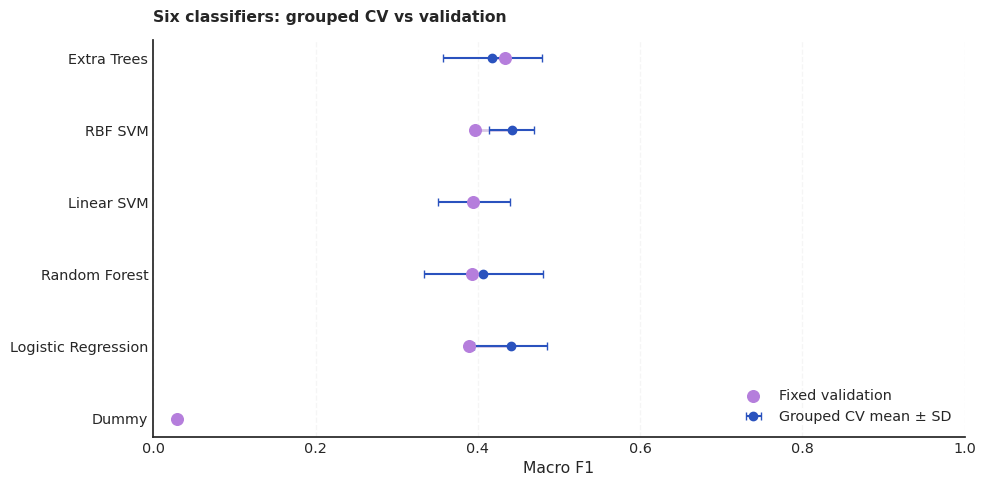

Best validation model: Extra Trees (Macro F1 0.434); grouped CV 0.418 ± 0.061.


In [ ]:
fig, ax = plt.subplots(figsize=(10,5))
p = comparison.sort_values('validation_f1')
ypos = np.arange(len(p))
a,b = p.cv_f1.to_numpy(),p.validation_f1.to_numpy()
ax.hlines(ypos,np.minimum(a,b),np.maximum(a,b),color='#D8C8E6',lw=2)
ax.errorbar(a,ypos,xerr=p.cv_sd,fmt='o',capsize=3,color=BLUE,label='Grouped CV mean ± SD')
ax.scatter(b,ypos,s=70,color=PURPLE,zorder=3,label='Fixed validation')
ax.set(yticks=ypos,yticklabels=p.model.map(pretty),xlabel='Macro F1',xlim=(0,1))
style_ax(ax,'Six classifiers: grouped CV vs validation',grid='x')
ax.legend(frameon=False,loc='lower right')
plt.tight_layout();save_plot(fig,'model_comparison.png')
win = comparison.iloc[0]
print(f"Best validation model: {pretty(win.model)} (Macro F1 {win.validation_f1:.3f}); grouped CV {win.cv_f1:.3f} ± {win.cv_sd:.3f}.")

## 6. Acoustic feature ablation
Three representative model families are compared on MFCC, prosodic, spectral, and combined features. Hyperparameters remain fixed at those tuned on all 39 features: this isolates feature groups but is not a separately optimized model search.

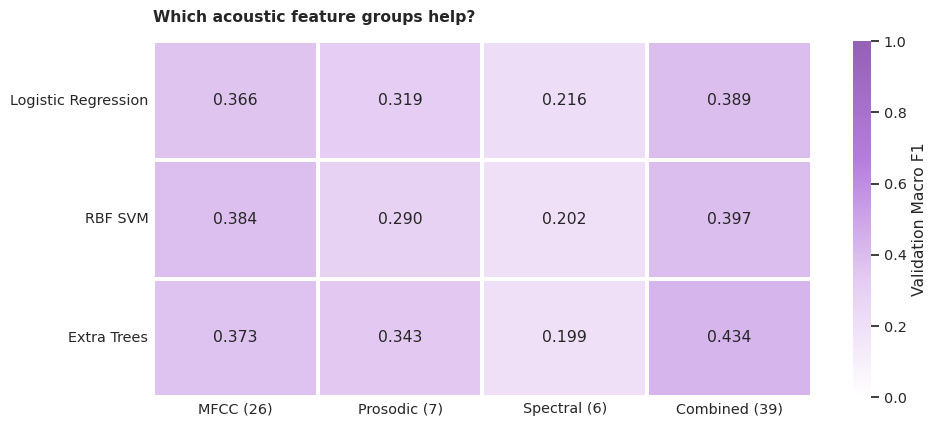

Ablation best: Extra Trees, Combined (39), validation Macro F1 0.434.
Ablation is exploratory; it does not replace the preselected full-feature baseline.


In [ ]:
# Controlled ablation: use each model family’s tuned hyperparameters from the full-feature search.
# Fit a new estimator for every feature subset, but do not repeat 12 expensive grid searches.
from sklearn.base import clone
family_names = ['logistic_regression','svm_rbf','extra_trees']
abl_rows = []
for family in family_names:
    for set_name, cols in FEATURE_SETS.items():
        estimator = clone(searches[family].best_estimator_)
        fold_f1 = []
        for train_idx, valid_idx in cv_splits:
            fit = clone(estimator).fit(X_train.iloc[train_idx][cols],y_train.iloc[train_idx])
            fold_f1.append(f1_score(y_train.iloc[valid_idx], fit.predict(X_train.iloc[valid_idx][cols]),
                                    labels=EMOTIONS,average='macro',zero_division=0))
        estimator.fit(X_train[cols],y_train)
        abl_rows.append({'model':family,'feature_set':set_name,'features':len(cols),
                         'cv_macro_f1':np.mean(fold_f1),'validation_macro_f1':f1_score(
                         y_val,estimator.predict(X_val[cols]),labels=EMOTIONS,average='macro',zero_division=0)})
ablation_df = pd.DataFrame(abl_rows)
ablation_df.to_csv(METRICS_DIR/'feature_ablation.csv',index=False)
heat = ablation_df.pivot(index='model',columns='feature_set',values='validation_macro_f1')
heat = heat.reindex(index=family_names,columns=list(FEATURE_SETS))
heat.index = [pretty(m) for m in heat.index]
fig,ax = plt.subplots(figsize=(10,4.4))
sns.heatmap(heat,annot=True,fmt='.3f',cmap=SEQUENTIAL,vmin=0,vmax=1,
            linewidths=1.6,linecolor='white',cbar_kws={'label':'Validation Macro F1'},ax=ax)
ax.set(xlabel='',ylabel='')
ax.tick_params(axis='both',labelrotation=0,length=0)
ax.set_title('Which acoustic feature groups help?',loc='left',fontweight='bold',pad=14)
plt.tight_layout();save_plot(fig,'ablation_heatmap.png')
best = ablation_df.sort_values('validation_macro_f1',ascending=False).iloc[0]
print(f"Ablation best: {pretty(best.model)}, {best.feature_set}, validation Macro F1 {best.validation_macro_f1:.3f}.")
print('Ablation is exploratory; it does not replace the preselected full-feature baseline.')

## 7. Regularization and generalization study

The original models remain the reference baselines. Four targeted alternatives are evaluated under **the same GroupKFold splits**: restricted Extra Trees, a wider RBF SVM regularization search, PCA + RBF SVM, and univariate feature selection + RBF SVM. Standardization, PCA and feature selection are fitted **inside** each cross-validation training fold. These choices are assessed by CV and fixed validation only; no test records enter this selection. A smaller train–CV gap is useful only if held-out performance is not sacrificed.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

regularized_models = {
    'extra_trees_regularized': {
        'steps': [('classifier', ExtraTreesClassifier(n_estimators=200, random_state=SEED, n_jobs=1))],
        'grid': {
            'classifier__min_samples_leaf': [2, 5, 10],
            'classifier__max_depth': [8, 16, None],
            'classifier__max_features': ['sqrt', 0.7],
        },
    },
    'svm_rbf_regularized': {
        'steps': [('scaler', StandardScaler()), ('classifier', SVC(kernel='rbf'))],
        'grid': {
            'classifier__C': [0.03, 0.3, 3, 30],
            'classifier__gamma': ['scale', 0.003, 0.03],
        },
    },
    'svm_rbf_pca': {
        'steps': [('scaler', StandardScaler()), ('pca', PCA(random_state=SEED)),
                  ('classifier', SVC(kernel='rbf'))],
        'grid': {
            'pca__n_components': [10, 18, 26],
            'classifier__C': [0.3, 3, 30],
            'classifier__gamma': ['scale'],
        },
    },
    'svm_rbf_selectk': {
        'steps': [('scaler', StandardScaler()), ('select', SelectKBest(score_func=f_classif)),
                  ('classifier', SVC(kernel='rbf'))],
        'grid': {
            'select__k': [12, 26, 39],
            'classifier__C': [0.3, 3, 30],
            'classifier__gamma': ['scale'],
        },
    },
}

# FAST_MODE (defined above) is only for checking code, not reporting final metrics.
regularized_searches, regularized_rows = {}, []
for name, spec in regularized_models.items():
    grid = {key: (values[:1] if FAST_MODE else values)
            for key, values in spec['grid'].items()}
    search = GridSearchCV(
        Pipeline(spec['steps']), grid, cv=cv_splits,
        scoring='f1_macro', refit=True, n_jobs=-1,
        error_score='raise', return_train_score=True
    )
    print('Regularization experiment:', name)
    search.fit(X_train, y_train)
    regularized_searches[name] = search
    idx = search.best_index_
    model = search.best_estimator_
    val_pred = model.predict(X_val)
    regularized_rows.append({
        'model': name,
        'cv_f1': float(search.best_score_),
        'cv_sd': float(search.cv_results_['std_test_score'][idx]),
        'train_f1': f1_score(y_train, model.predict(X_train),
                             labels=EMOTIONS, average='macro', zero_division=0),
        'cv_train_f1': float(search.cv_results_['mean_train_score'][idx]),
        'validation_f1': f1_score(y_val, val_pred, labels=EMOTIONS,
                                  average='macro', zero_division=0),
        'validation_accuracy': accuracy_score(y_val, val_pred),
        'validation_balanced_accuracy': balanced_accuracy_score(y_val, val_pred),
        'best_params': json.dumps(search.best_params_),
    })

regularized_df = pd.DataFrame(regularized_rows)
regularized_df.to_csv(METRICS_DIR/'regularization_results.csv', index=False)

# Original six and additional configurations use identical speaker splits and target metric.
all_results = pd.concat([comparison.assign(source='Original baseline'),
                         regularized_df.assign(source='Regularization study')],
                        ignore_index=True)
all_results['gap_train_cv'] = all_results.train_f1 - all_results.cv_f1
all_results = all_results.sort_values(['validation_f1', 'cv_f1'],
                                      ascending=False).reset_index(drop=True)
all_results.to_csv(METRICS_DIR/'all_model_comparison.csv', index=False)

label_names = {**{key:pretty(key) for key in models},
    'extra_trees_regularized':'Extra Trees · regularized',
    'svm_rbf_regularized':'RBF SVM · regularized',
    'svm_rbf_pca':'PCA + RBF SVM',
    'svm_rbf_selectk':'SelectKBest + RBF SVM'}
display(all_results[['model','source','train_f1','cv_f1','cv_sd',
                     'validation_f1','gap_train_cv']].round(3))

Regularization experiment: extra_trees_regularized
Regularization experiment: svm_rbf_regularized
Regularization experiment: svm_rbf_pca
Regularization experiment: svm_rbf_selectk


,model,source,train_f1,cv_f1,cv_sd,validation_f1,gap_train_cv
0,svm_rbf_selectk,Regularization study,0.902,0.406,0.035,0.441,0.495
1,svm_rbf_regularized,Regularization study,0.678,0.409,0.036,0.434,0.269
2,extra_trees,Original baseline,1.000,0.418,0.061,0.434,0.582
3,svm_rbf_pca,Regularization study,0.897,0.387,0.050,0.407,0.510
4,svm_rbf,Original baseline,0.692,0.442,0.027,0.397,0.250
5,extra_trees_regularized,Regularization study,1.000,0.416,0.065,0.396,0.584
6,svm_linear,Original baseline,0.669,0.395,0.045,0.394,0.274
7,random_forest,Original baseline,1.000,0.407,0.074,0.392,0.593
8,logistic_regression,Original baseline,0.644,0.440,0.045,0.389,0.204
9,dummy_most_frequent,Original baseline,0.029,0.029,0.000,0.029,0.000


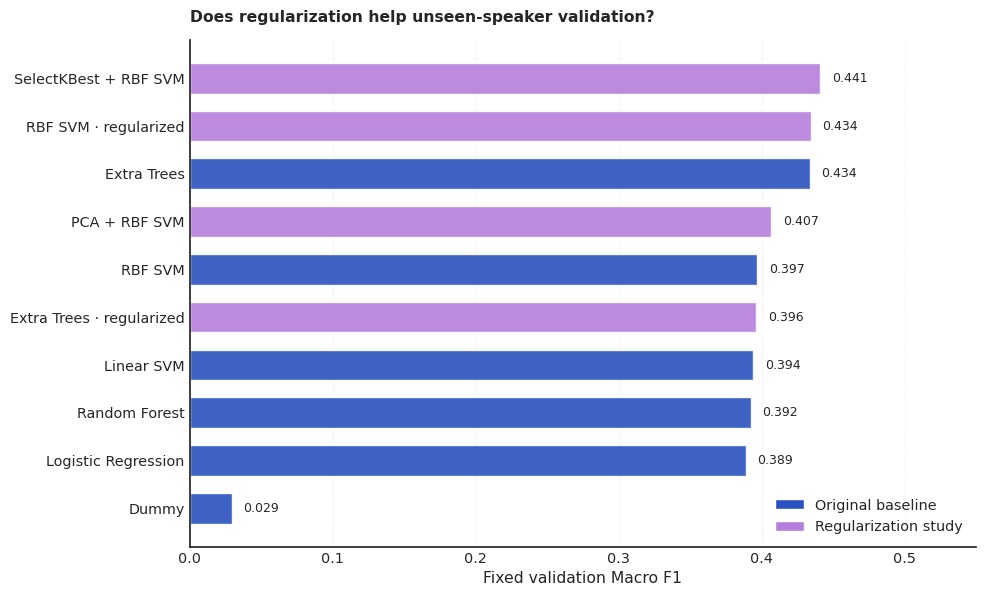

Original best: Extra Trees | validation Macro F1 0.434
Best among all studied: SelectKBest + RBF SVM | validation Macro F1 0.441 (+0.008)
Training F1 and train–CV gaps are descriptive diagnostics, not separate tuning targets.


In [ ]:
# A compact diagnostic: comparison on validation, with train–CV gaps in the table.
p = all_results.sort_values('validation_f1')
fig, ax = plt.subplots(figsize=(10, 6.1))
colors = [PURPLE if source == 'Regularization study' else BLUE for source in p.source]
ypos = np.arange(len(p))
ax.barh(ypos, p.validation_f1, color=colors, height=.64, alpha=.9)
ax.set(yticks=ypos, yticklabels=[label_names[name] for name in p.model],
       xlabel='Fixed validation Macro F1', xlim=(0, min(1, max(.55, p.validation_f1.max()+.08))))
for yidx, val in zip(ypos, p.validation_f1):
    ax.text(val+.008, yidx, f'{val:.3f}', va='center', fontsize=9)
style_ax(ax, 'Does regularization help unseen-speaker validation?', grid='x')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=BLUE,label='Original baseline'),
                   Patch(facecolor=PURPLE,label='Regularization study')],
          loc='lower right', frameon=False)
plt.tight_layout();save_plot(fig,'regularization_validation.png')

base_best = comparison.iloc[0]
new_best = all_results.iloc[0]
delta = new_best.validation_f1 - base_best.validation_f1
print(f'Original best: {label_names[base_best.model]} | validation Macro F1 {base_best.validation_f1:.3f}')
print(f'Best among all studied: {label_names[new_best.model]} | validation Macro F1 {new_best.validation_f1:.3f} ({delta:+.3f})')
print('Training F1 and train–CV gaps are descriptive diagnostics, not separate tuning targets.')

## 8. Frozen model choice

Choose the highest **fixed-validation Macro F1** among the six baselines and the four planned regularization configurations; break ties by train-only CV score. The selection rule is fixed before any new test evaluation. The selected train-fitted pipeline and exact feature order are saved for notebook 05. The original-best baseline is also saved **for validation diagnostics only**.

In [ ]:
selected = all_results.iloc[0]
SELECTED_NAME = str(selected.model)
SELECTED_SEARCH = (regularized_searches.get(SELECTED_NAME)
                   if SELECTED_NAME in regularized_searches else searches[SELECTED_NAME])
SELECTED_ESTIMATOR = SELECTED_SEARCH.best_estimator_
ORIGINAL_NAME = str(comparison.iloc[0].model)
ORIGINAL_ESTIMATOR = searches[ORIGINAL_NAME].best_estimator_

config = {
    'seed':SEED, 'train_actors':list(range(1,13)),
    'validation_actors':list(range(13,19)), 'test_actors':list(range(19,25)),
    'feature_names':FEATURE_COLS, 'selected_model':SELECTED_NAME,
    'selected_params':SELECTED_SEARCH.best_params_,
    'selected_validation_f1':float(selected.validation_f1),
    'selected_cv_f1':float(selected.cv_f1),
    'original_baseline_model':ORIGINAL_NAME,
    'original_baseline_validation_f1':float(comparison.iloc[0].validation_f1),
    'data_sha256':DATA_SHA256, 'selection_metric':'validation_macro_f1',
    'model_full_features_only':True, 'fast_mode':FAST_MODE,
    'historical_test_warning':'Test actors were inspected in previous notebook versions; descriptive evaluation is not a new blind benchmark.',
    'python_version':platform.python_version()
}
(METRICS_DIR/'frozen_config.json').write_text(json.dumps(config,indent=2),encoding='utf8')
joblib.dump(SELECTED_ESTIMATOR, OUTPUT_DIR/'validation_selected_pipeline.joblib')
joblib.dump(ORIGINAL_ESTIMATOR, OUTPUT_DIR/'original_baseline_pipeline.joblib')
print(f"Frozen: {label_names[SELECTED_NAME]}; validation Macro F1 {selected.validation_f1:.3f}")
print(f"Original best: {label_names[ORIGINAL_NAME]}; validation Macro F1 {comparison.iloc[0].validation_f1:.3f}")
print('No test data used for this selection.')

Frozen: SelectKBest + RBF SVM; validation Macro F1 0.441
Original best: Extra Trees; validation Macro F1 0.434
No test data used for this selection.


### Interpretation and limitations
Compare validation and CV Macro F1 and the train–CV gap in the results table. Stronger regularization can reduce memorization, but a smaller gap alone is not evidence of better generalization. The ablation, PCA and K-Means results describe feature structure; they do not drive the frozen model selection.


---
# Part II — V2 controlled experiments: temporal dynamics × silence trimming

**Preservation of previous work:** Sections 1–8 above are retained unchanged, including train-only PCA, clustering, six model families, feature-group ablation, regularization, and the original frozen-model decision. Their weaker results are informative evidence, not discarded trials.

**New research question.** On the **same speaker-disjoint split**, do 81 dynamic descriptors (MFCC first/second derivatives plus RMS changes) and/or less aggressive trimming improve emotion recognition? Inputs are the six versioned CSV files produced by Notebook 03 v2.

**Important:** These are *new* experiments after the historical test has already been inspected. Use training-speaker GroupKFold as the **primary** comparison and fixed validation as descriptive secondary evidence. Do not inspect or re-select on actors 19–24. Results are exploratory; an apparent gain is not proof of causation. The original Notebook 05 still describes the legacy frozen selection unless explicitly updated later.

To preserve past outputs, all V2 artifacts go under **`results/04_ml_v2/`** rather than overwriting `results/04_ml/`. The original `ravdess_features.csv` and models are unchanged.

In [ ]:
# V2 input discovery and strict consistency checks (no audio extraction here)
V2_VERSION = 'v2_delta_rmsdiff_20261104'
V2_DIR = PROJECT_DIR / 'data/processed' / f'ravdess_{V2_VERSION}'
V2_RESULTS_DIR = PROJECT_DIR / 'results/04_ml_v2'
V2_METRICS_DIR = V2_RESULTS_DIR / 'metrics'
V2_FIGURES_DIR = V2_RESULTS_DIR / 'figures'
for path in (V2_METRICS_DIR, V2_FIGURES_DIR):
    path.mkdir(parents=True, exist_ok=True)

V2_MODES = ['trim30', 'trim50', 'no_trim']
V2_REPS = ['static', 'enriched']
V2_CONDITIONS = [(m, r) for m in V2_MODES for r in V2_REPS]
V2_META_COLS = list(df.columns.difference(FEATURE_COLS))
V2_REFERENCE = df.set_index('relative_path')
V2_INPUTS = {}
V2_INPUT_HASHES = {}
V2_FEATURES = {}

for mode, rep in V2_CONDITIONS:
    fp = V2_DIR / f'features_{mode}_{rep}.csv'
    if not fp.is_file():
        raise FileNotFoundError(f'Missing Notebook 03 V2 output: {fp}')
    table = pd.read_csv(fp)
    if len(table) != 1440 or not table.relative_path.is_unique:
        raise AssertionError(f'Bad row count or duplicate files: {fp}')
    table = table.sort_values('relative_path').reset_index(drop=True)
    if not table.relative_path.equals(df.relative_path):
        raise AssertionError(f'Recording keys/order differ from baseline: {fp}')
    for col in ['emotion', 'actor_id']:
        if not table[col].astype(str).equals(df[col].astype(str)):
            raise AssertionError(f'Metadata mismatch in {col}: {fp}')
    extra = [c for c in table.columns if c not in V2_META_COLS and c not in FEATURE_COLS]
    cols = FEATURE_COLS + extra
    expected_count = 39 if rep == 'static' else 120
    if len(cols) != expected_count or not set(cols).issubset(table.columns):
        raise AssertionError(f'Expected {expected_count} features: {fp}; got {len(cols)}')
    if len(set(cols)) != expected_count or not np.isfinite(table[cols].to_numpy(dtype=float)).all():
        raise AssertionError(f'Duplicate or nonfinite acoustic values: {fp}')
    V2_INPUTS[(mode, rep)] = table
    V2_INPUT_HASHES[f'{mode}_{rep}'] = hashlib.sha256(fp.read_bytes()).hexdigest()
    V2_FEATURES[(mode, rep)] = cols
    print(f'{mode:8s} {rep:8s}: {table.shape}; acoustic={len(cols)}')

# Validation of the static trim30 equivalence (CSV floating-point representation may differ).
np.testing.assert_allclose(
    V2_INPUTS[('trim30','static')][FEATURE_COLS].to_numpy(dtype=float),
    df[FEATURE_COLS].to_numpy(dtype=float), rtol=1e-12, atol=1e-10
)
assert len(set(V2_FEATURES[('trim30','enriched')]) - set(FEATURE_COLS)) == 81
print('Static trim30 agrees with original baseline within strict numerical tolerance.')
print('Actors 19–24 are reserved for descriptive evaluation ONLY; not accessed in V2 fits.')

trim30   static  : (1440, 49); acoustic=39
trim30   enriched: (1440, 130); acoustic=120
trim50   static  : (1440, 49); acoustic=39
trim50   enriched: (1440, 130); acoustic=120
no_trim  static  : (1440, 49); acoustic=39
no_trim  enriched: (1440, 130); acoustic=120
Static trim30 agrees with original baseline within strict numerical tolerance.
Actors 19–24 are reserved for descriptive evaluation ONLY; not accessed in V2 fits.


## 9. Controlled comparison: four fixed model families × six feature tables

The model configurations below are **fixed before this V2 experiment** (they are not tuned on V2 validation). For each condition, the **same 3 grouped CV folds** are used, with `StandardScaler` inside the pipeline. The fixed validation set is evaluated as an additional diagnostic, never used to choose a "winner". This design limits search multiplicity and makes relative changes easier to interpret.

We include Logistic Regression, Linear SVM, RBF SVM, and Extra Trees. The **original six-family and regularization plots above remain part of the historical investigation**. The default run computes 72 fold fits plus 24 train/validation refits, no audio decoding or pYIN.

The dataset is an acted, balanced-by-design corpus with only 24 speakers. Fold-to-fold uncertainty matters; numerical improvements may not generalize beyond these speakers.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

V2_MODELS = {
    'logistic_regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(C=0.3, max_iter=5000, random_state=SEED))
    ]),
    'svm_linear': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LinearSVC(C=0.1, max_iter=20000, random_state=SEED))
    ]),
    'svm_rbf': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(kernel='rbf', C=3.0, gamma='scale'))
    ]),
    'extra_trees': Pipeline([
        ('scaler', 'passthrough'),
        ('classifier', ExtraTreesClassifier(n_estimators=200, min_samples_leaf=4,
                                           random_state=SEED, n_jobs=1))
    ])
}

V2_CV_ROWS = []
V2_FOLD_ROWS = []
V2_VAL_ROWS = []
V2_VAL_PREDICTIONS = {}
for mode, rep in V2_CONDITIONS:
    table = V2_INPUTS[(mode, rep)]
    cols = V2_FEATURES[(mode, rep)]
    Xt = table.loc[train_mask, cols].reset_index(drop=True)
    Xv = table.loc[val_mask, cols].reset_index(drop=True)
    assert len(Xt) == len(y_train) == 720 and len(Xv) == len(y_val) == 360
    assert (table.loc[train_mask,'actor_id'].astype(int).reset_index(drop=True).equals(g_train))
    for name, template in V2_MODELS.items():
        fold_f1, fold_train = [], []
        for fold, (idx_train, idx_cv) in enumerate(cv_splits, start=1):
            estimator = clone(template).fit(Xt.iloc[idx_train], y_train.iloc[idx_train])
            predicted = estimator.predict(Xt.iloc[idx_cv])
            score = f1_score(y_train.iloc[idx_cv], predicted,
                             labels=EMOTIONS, average='macro', zero_division=0)
            train_score = f1_score(y_train.iloc[idx_train],
                                   estimator.predict(Xt.iloc[idx_train]),
                                   labels=EMOTIONS, average='macro', zero_division=0)
            fold_f1.append(float(score))
            fold_train.append(float(train_score))
            V2_FOLD_ROWS.append({'mode':mode, 'representation':rep, 'model':name,
                                 'fold':fold, 'cv_f1':float(score),
                                 'train_fold_f1':float(train_score)})
        full_estimator = clone(template).fit(Xt, y_train)
        predicted = full_estimator.predict(Xv)
        V2_VAL_PREDICTIONS[(mode,rep,name)] = predicted
        val_f1 = f1_score(y_val, predicted, labels=EMOTIONS,
                          average='macro', zero_division=0)
        V2_CV_ROWS.append({'mode':mode, 'representation':rep, 'model':name,
                           'n_features':len(cols),
                           'cv_macro_f1':float(np.mean(fold_f1)),
                           'cv_sd':float(np.std(fold_f1, ddof=1)),
                           'cv_train_macro_f1':float(np.mean(fold_train)),
                           'cv_gap':float(np.mean(fold_train)-np.mean(fold_f1))})
        V2_VAL_ROWS.append({'mode':mode, 'representation':rep, 'model':name,
                            'validation_macro_f1':float(val_f1),
                            'validation_accuracy':float(accuracy_score(y_val, predicted)),
                            'validation_balanced_accuracy':float(balanced_accuracy_score(y_val, predicted))})
    print('Completed V2:', mode, rep)

v2_cv = pd.DataFrame(V2_CV_ROWS)
v2_folds = pd.DataFrame(V2_FOLD_ROWS)
v2_validation = pd.DataFrame(V2_VAL_ROWS)
v2_summary = v2_cv.merge(v2_validation, on=['mode','representation','model'],validate='one_to_one')
assert len(v2_summary)==24 and len(v2_folds)==72
v2_cv.to_csv(V2_METRICS_DIR/'grouped_cv_summary.csv',index=False)
v2_folds.to_csv(V2_METRICS_DIR/'grouped_cv_fold_scores.csv',index=False)
v2_validation.to_csv(V2_METRICS_DIR/'fixed_validation_descriptive.csv',index=False)
v2_summary.to_csv(V2_METRICS_DIR/'all_conditions.csv',index=False)
display(v2_summary.sort_values(['model','mode','representation']).round(3))

Completed V2: trim30 static
Completed V2: trim30 enriched
Completed V2: trim50 static
Completed V2: trim50 enriched
Completed V2: no_trim static
Completed V2: no_trim enriched


,mode,representation,model,n_features,cv_macro_f1,cv_sd,cv_train_macro_f1,cv_gap,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
23,no_trim,enriched,extra_trees,120,0.356,0.048,1.000,0.644,0.409,0.444,0.422
19,no_trim,static,extra_trees,39,0.349,0.067,0.994,0.646,0.383,0.408,0.388
7,trim30,enriched,extra_trees,120,0.439,0.066,0.995,0.556,0.388,0.417,0.396
3,trim30,static,extra_trees,39,0.379,0.063,0.996,0.617,0.391,0.414,0.396
15,trim50,enriched,extra_trees,120,0.354,0.025,0.997,0.643,0.377,0.425,0.398
11,trim50,static,extra_trees,39,0.338,0.059,0.993,0.656,0.383,0.422,0.396
20,no_trim,enriched,logistic_regression,120,0.414,0.030,0.951,0.538,0.404,0.419,0.417
16,no_trim,static,logistic_regression,39,0.384,0.054,0.749,0.365,0.374,0.400,0.383
4,trim30,enriched,logistic_regression,120,0.460,0.032,0.954,0.494,0.385,0.411,0.409
0,trim30,static,logistic_regression,39,0.390,0.063,0.771,0.382,0.380,0.400,0.385


## 10. Ablation heatmaps: what improves unseen-speaker CV?

The heatmap compares **cross-validated Macro F1** on *training speakers*. The validation heatmap is complementary and does not define the best configuration. Blue/lavender visual language from the original Notebook 04 is preserved.

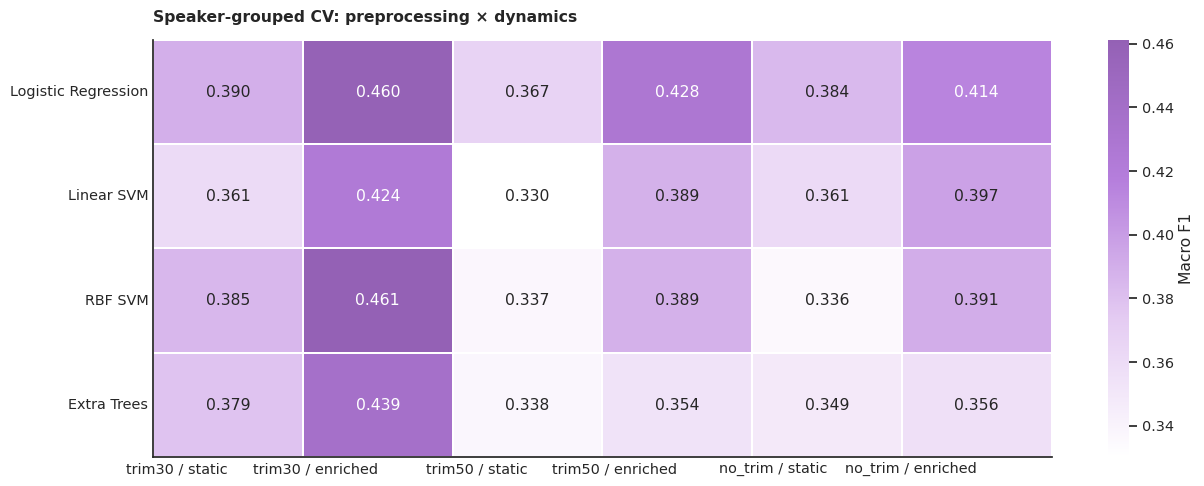

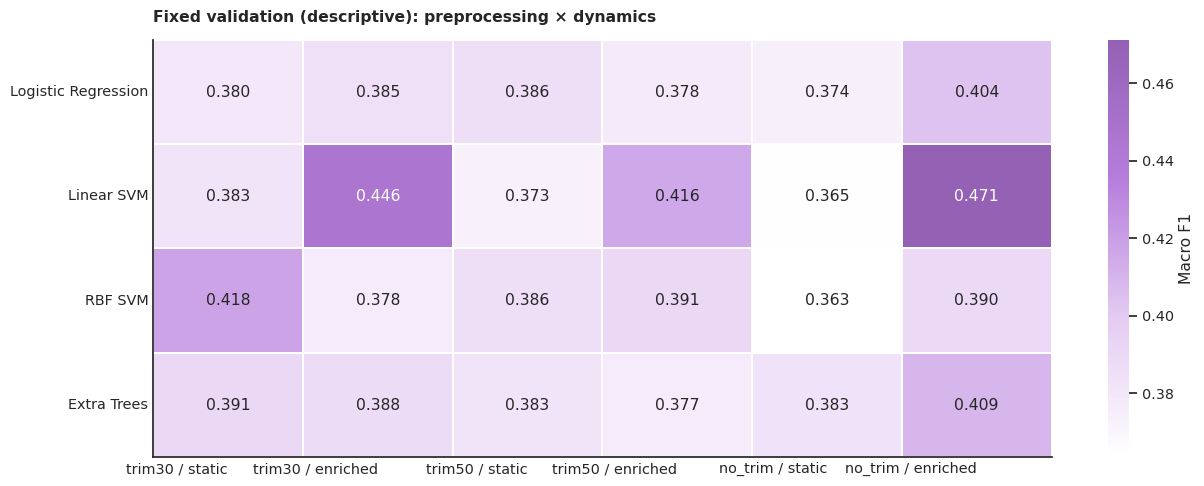

In [ ]:
for metric, title, filename in [
    ('cv_macro_f1', 'Speaker-grouped CV: preprocessing × dynamics', 'v2_cv_heatmap.png'),
    ('validation_macro_f1', 'Fixed validation (descriptive): preprocessing × dynamics', 'v2_validation_heatmap.png')
]:
    view = v2_summary.copy()
    view['condition'] = view['mode'] + ' / ' + view['representation']
    pivot = view.pivot(index='model', columns='condition', values=metric)
    ordered_cols = [m+' / '+r for m,r in V2_CONDITIONS]
    pivot = pivot.reindex(index=list(V2_MODELS), columns=ordered_cols)
    pivot.index = [pretty(m) for m in pivot.index]
    fig, ax = plt.subplots(figsize=(13, 5))
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap=SEQUENTIAL,
                linewidths=1.2, linecolor='white',
                cbar_kws={'label':'Macro F1'}, ax=ax)
    ax.set(xlabel='', ylabel='')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')
    style_ax(ax, title, grid='y')
    plt.tight_layout()
    fig.savefig(V2_FIGURES_DIR/filename, dpi=170, bbox_inches='tight')
    plt.show()

## 11. Paired-fold diagnostics and train–CV generalization gaps

**Within each model**, compare dynamic versus static features using the same three held-out speaker groups. These are **paired descriptive differences**, not confidence intervals or significance tests; with three folds, the observed variance is unstable. We also visualize the train–CV gap to see whether a better training score translates into unseen-speaker performance.

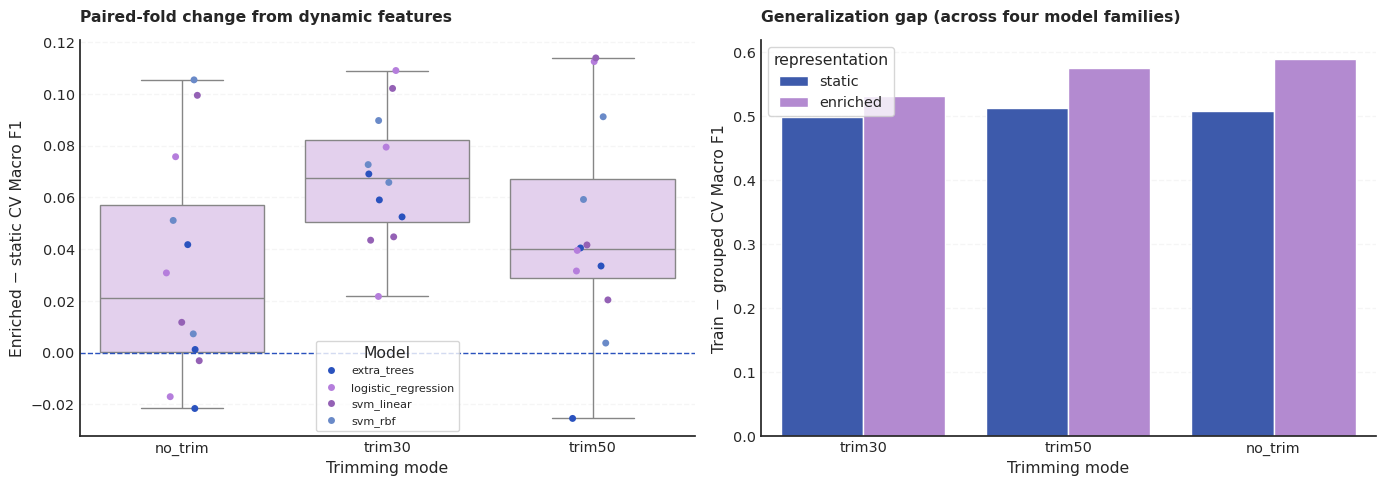

mean    min    max
mode    model                                   
no_trim extra_trees          0.007 -0.022  0.042
        logistic_regression  0.030 -0.017  0.076
        svm_linear           0.036 -0.003  0.100
        svm_rbf              0.055  0.007  0.105
trim30  extra_trees          0.060  0.052  0.069
        logistic_regression  0.070  0.022  0.109
        svm_linear           0.063  0.043  0.102
        svm_rbf              0.076  0.066  0.090
trim50  extra_trees          0.016 -0.025  0.040
        logistic_regression  0.061  0.032  0.113
        svm_linear           0.059  0.020  0.114
        svm_rbf              0.051  0.004  0.091

In [ ]:
paired = v2_folds.pivot_table(index=['mode','model','fold'],
                              columns='representation', values='cv_f1').reset_index()
paired['delta_enriched_minus_static'] = paired['enriched']-paired['static']
assert len(paired) == 36
paired.to_csv(V2_METRICS_DIR/'paired_fold_differences.csv',index=False)
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.boxplot(data=paired, x='mode', y='delta_enriched_minus_static',
            color='#E4CBF2', ax=axes[0])
sns.stripplot(data=paired, x='mode', y='delta_enriched_minus_static',
              hue='model', palette=MODEL_COLORS[:4], dodge=False, ax=axes[0], size=5)
axes[0].axhline(0,color=BLUE, ls='--', lw=1)
axes[0].set(xlabel='Trimming mode', ylabel='Enriched − static CV Macro F1')
axes[0].legend(title='Model', fontsize=8)
style_ax(axes[0],'Paired-fold change from dynamic features')

summary_plot=v2_summary.copy()
summary_plot['condition']=summary_plot['mode']+' / '+summary_plot['representation']
sns.barplot(data=summary_plot, x='mode', y='cv_gap', hue='representation',
            palette={'static':BLUE,'enriched':PURPLE}, errorbar=None, ax=axes[1])
axes[1].set(xlabel='Trimming mode',ylabel='Train − grouped CV Macro F1')
style_ax(axes[1],'Generalization gap (across four model families)')
plt.tight_layout()
fig.savefig(V2_FIGURES_DIR/'v2_dynamics_gap_diagnostics.png',dpi=170,bbox_inches='tight')
plt.show()
display(paired.groupby(['mode','model']).delta_enriched_minus_static.agg(['mean','min','max']).round(3))

## 12. Class-wise diagnostics and reproducibility hand-off

For interpretation, plot **one predefined comparison** on validation: RBF SVM with trim30, static versus enriched. This is not selected by the validation score and shows which emotions change for the same model when dynamics are added. We do not access reserved test actors in this notebook.

Save the *CV-leading configuration* as an **exploratory V2 candidate**, separately from the original Notebook 04 frozen model. We do not overwrite the old frozen choice or claim the new candidate was chosen on an untouched test set.

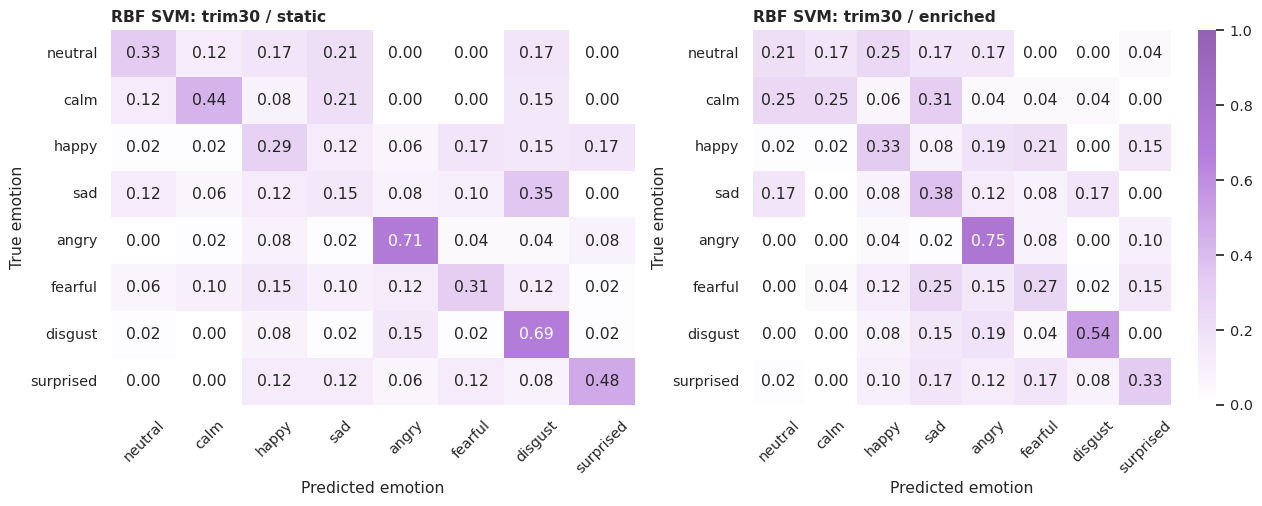

V2 exploratory CV leader: ('trim30', 'enriched') svm_rbf
Grouped CV Macro F1: 0.461; fixed validation (descriptive): 0.378
Saved V2 tables, plots, model and manifest to: /content/drive/MyDrive/speech-emotion-recognition-project-d/results/04_ml_v2
Next: Notebook 05 V2 evaluation should retain historical test caveat.


In [ ]:
from sklearn.metrics import classification_report
fig, axes = plt.subplots(1,2,figsize=(13,5.2))
for ax, rep in zip(axes,['static','enriched']):
    preds = V2_VAL_PREDICTIONS[('trim30',rep,'svm_rbf')]
    matrix=confusion_matrix(y_val,preds,labels=EMOTIONS,normalize='true')
    sns.heatmap(matrix,annot=True,fmt='.2f',vmin=0,vmax=1,cmap=SEQUENTIAL,
                xticklabels=EMOTIONS,yticklabels=EMOTIONS,
                ax=ax,cbar=(rep=='enriched'))
    ax.tick_params(axis='x',rotation=45)
    ax.set(xlabel='Predicted emotion',ylabel='True emotion')
    ax.set_title('RBF SVM: trim30 / '+rep,loc='left',fontweight='bold')
plt.tight_layout()
fig.savefig(V2_FIGURES_DIR/'v2_fixed_rbf_confusion_comparison.png',dpi=170,bbox_inches='tight')
plt.show()

# Only GroupKFold mean determines which exploratory V2 candidate to retain.
# The validation score is descriptive and does not break ties.
ranked=v2_summary.sort_values(['cv_macro_f1','cv_sd','model','mode','representation'],
                              ascending=[False,True,True,True,True]).reset_index(drop=True)
chosen=ranked.iloc[0]
selected_key=(str(chosen['mode']),str(chosen['representation']))
chosen_cols=V2_FEATURES[selected_key]
chosen_table=V2_INPUTS[selected_key]
chosen_xt=chosen_table.loc[train_mask,chosen_cols].reset_index(drop=True)
exploratory_estimator=clone(V2_MODELS[str(chosen['model'])]).fit(chosen_xt,y_train)
joblib.dump(exploratory_estimator,V2_RESULTS_DIR/'exploratory_cv_candidate.joblib')
manifest={
    'research_stage':'Exploratory V2, not a new blind test',
    'selection_basis':'mean of 3 training-speaker GroupKFold Macro F1; validation descriptive only',
    'chosen':{'mode':selected_key[0], 'representation':selected_key[1],
              'model':str(chosen['model']), 'cv_macro_f1':float(chosen['cv_macro_f1']),
              'validation_macro_f1_descriptive':float(chosen['validation_macro_f1'])},
    'feature_names':chosen_cols,
    'train_actors':list(range(1,13)), 'validation_actors':list(range(13,19)),
    'historically_inspected_test_actors':list(range(19,25)),
    'input_sha256':V2_INPUT_HASHES,
    'model_parameters':{k:repr(v) for k,v in exploratory_estimator.get_params(deep=False).items()},
    'n_cv_folds':3,
    'note':'Original Notebook 05 frozen selection is preserved; do not call V2 test evaluation blind.'
}
(V2_METRICS_DIR/'exploratory_v2_manifest.json').write_text(
    json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('V2 exploratory CV leader:',selected_key,chosen['model'])
print(f"Grouped CV Macro F1: {chosen['cv_macro_f1']:.3f}; fixed validation (descriptive): {chosen['validation_macro_f1']:.3f}")
print('Saved V2 tables, plots, model and manifest to:',V2_RESULTS_DIR)
print('Next: Notebook 05 V2 evaluation should retain historical test caveat.')